saved the figure
saved the animation


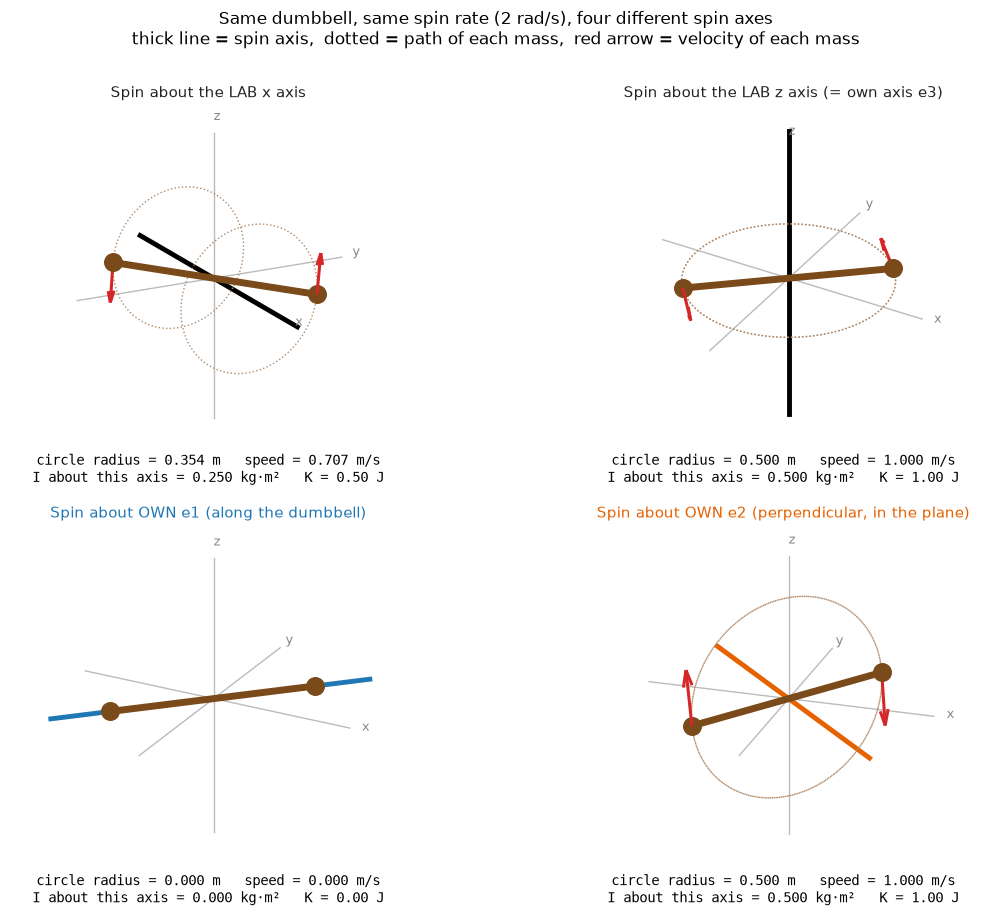

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.animation import FuncAnimation, PillowWriter  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the dumbbell and the four spin axes
#   What we have: two 1 kg masses at +-0.5 m along e1, tilted 45 deg from the lab x axis in the xy plane
#   What we want: the same dumbbell spun at 2 rad/s about four different axes
#   Why: to see how the spin differs for each axis and what I measures
#   e1 = (cos a, sin a, 0)  along the dumbbell
#   e2 = (-sin a, cos a, 0) perpendicular, in the plane
#   lab x = (1, 0, 0),  lab z = (0, 0, 1)
# ---------------------------------------------------------------
M_EACH, HALF, OMEGA = 1.0, 0.5, 2.0
alpha = np.deg2rad(45.0)
e1 = np.array([np.cos(alpha), np.sin(alpha), 0.0])
e2 = np.array([-np.sin(alpha), np.cos(alpha), 0.0])
masses = np.array([HALF * e1, -HALF * e1])

CASES = [
    ("Spin about the LAB x axis", np.array([1.0, 0.0, 0.0]), "black"),
    ("Spin about the LAB z axis (= own axis e3)", np.array([0.0, 0.0, 1.0]), "black"),
    ("Spin about OWN e1 (along the dumbbell)", e1, "#1f77b4"),
    ("Spin about OWN e2 (perpendicular, in the plane)", e2, "#e66100"),
]

# ---------------------------------------------------------------
# STEP 2: what each spin does to the masses
#   What we have: a unit axis a and the mass positions r
#   What we want: radius of each circle, speed, I about that axis, and kinetic energy
#   Why: every mass moves on a circle around the axis, radius = distance from the axis
#   r_perp = |r - (r.a) a|,  v = omega r_perp,  I_axis = sum m r_perp^2,  K = 1/2 I_axis omega^2
# ---------------------------------------------------------------


def stats(axis):
    r_perp = np.linalg.norm(masses[0] - (masses[0] @ axis) * axis)
    speed = OMEGA * r_perp
    I_axis = 2 * M_EACH * r_perp**2
    K = 0.5 * I_axis * OMEGA**2
    return r_perp, speed, I_axis, K


def rotate(points, axis, theta):
    # Rodrigues rotation of each row of points about the unit axis by theta
    k = axis
    c, s = np.cos(theta), np.sin(theta)
    return points * c + np.cross(k, points) * s + np.outer(points @ k, k) * (1 - c)


# ---------------------------------------------------------------
# STEP 3: draw four 3D panels and animate the spin
#   What we have: the cases and the formulas above
#   What we want: a static picture and a looping animation
#   Why: to watch the masses go around circles of different sizes (or not move at all)
#   panel text: radius, speed, I about the axis, K
# ---------------------------------------------------------------
fig = plt.figure(figsize=(11.5, 9.5))
axes3d, bodies, state = [], [], []
th_circle = np.linspace(0, 2 * np.pi, 200)
VIEWS = [(18, -28), (32, -60), (24, -62), (22, -72)]  # (elev, azim) per panel

for idx, (title, axis, color) in enumerate(CASES):
    ax = fig.add_subplot(2, 2, idx + 1, projection="3d")
    axes3d.append(ax)
    r_perp, speed, I_axis, K = stats(axis)
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.8, 0.8)
    ax.set_zlim(-0.8, 0.8)
    ax.set_box_aspect((1, 1, 1), zoom=1.45)
    ax.set_axis_off()
    ax.view_init(elev=VIEWS[idx][0], azim=VIEWS[idx][1])
    for v, lab in ((np.array([1.0, 0, 0]), "x"), (np.array([0, 1.0, 0]), "y"), (np.array([0, 0, 1.0]), "z")):
        ax.plot(*(np.vstack([-0.7 * v, 0.7 * v]).T), color="#bbbbbb", lw=1)
        ax.text(*(0.76 * v), lab, color="#888888", fontsize=9)
    ax.plot(*(np.vstack([-0.78 * axis, 0.78 * axis]).T), color=color, lw=3.5)
    ax.text2D(0.5, 0.97, title, transform=ax.transAxes, ha="center", fontsize=10.5, color=color if color != "black" else "#222222")
    for m_pos in masses:
        circ = np.array([rotate(m_pos[None, :], axis, t)[0] for t in th_circle])
        ax.plot(circ[:, 0], circ[:, 1], circ[:, 2], color="#b08968", lw=1, ls=":")
    msg = (f"circle radius = {r_perp:.3f} m   speed = {speed:.3f} m/s\n"
           f"I about this axis = {I_axis:.3f} kg·m²   K = {K:.2f} J")
    ax.text2D(0.5, 0.0, msg, transform=ax.transAxes, ha="center", fontsize=10, family="monospace")
    line, = ax.plot([], [], [], color="#7a4a1a", lw=5)
    dots = ax.scatter([], [], [], s=160, color="#7a4a1a", depthshade=False)
    bodies.append((line, dots))
    state.append({"arrows": []})

fig.suptitle("Same dumbbell, same spin rate (2 rad/s), four different spin axes\n"
             "thick line = spin axis,  dotted = path of each mass,  red arrow = velocity of each mass", fontsize=12)
fig.subplots_adjust(left=0.0, right=1.0, top=0.90, bottom=0.04, wspace=0.0, hspace=0.06)


def update(frame, n_frames=72):
    theta = 2 * np.pi * frame / n_frames
    for (title, axis, color), ax, (line, dots), st in zip(CASES, axes3d, bodies, state):
        pos = rotate(masses, axis, theta)
        line.set_data(pos[:, 0], pos[:, 1])
        line.set_3d_properties(pos[:, 2])
        dots._offsets3d = (pos[:, 0], pos[:, 1], pos[:, 2])
        for ar in st["arrows"]:
            ar.remove()
        st["arrows"] = []
        for p in pos:
            v = OMEGA * np.cross(axis, p)  # velocity of the mass
            if np.linalg.norm(v) > 1e-9:
                st["arrows"].append(ax.quiver(*p, *(0.28 * v), color="#d62728", lw=2.2, arrow_length_ratio=0.3))
    return []


update(10)
static_path = os.path.join(RESULT_DIR, f"dumbbell_spin_axes_{TIMESTAMP}.png")
plt.savefig(static_path, dpi=170)
print("saved the figure")

anim = FuncAnimation(fig, update, frames=72, interval=50, blit=False)
gif_path = os.path.join(RESULT_DIR, f"dumbbell_spin_axes_{TIMESTAMP}.gif")
anim.save(gif_path, writer=PillowWriter(fps=20), dpi=70)
print("saved the animation")
plt.show()

saved the figure


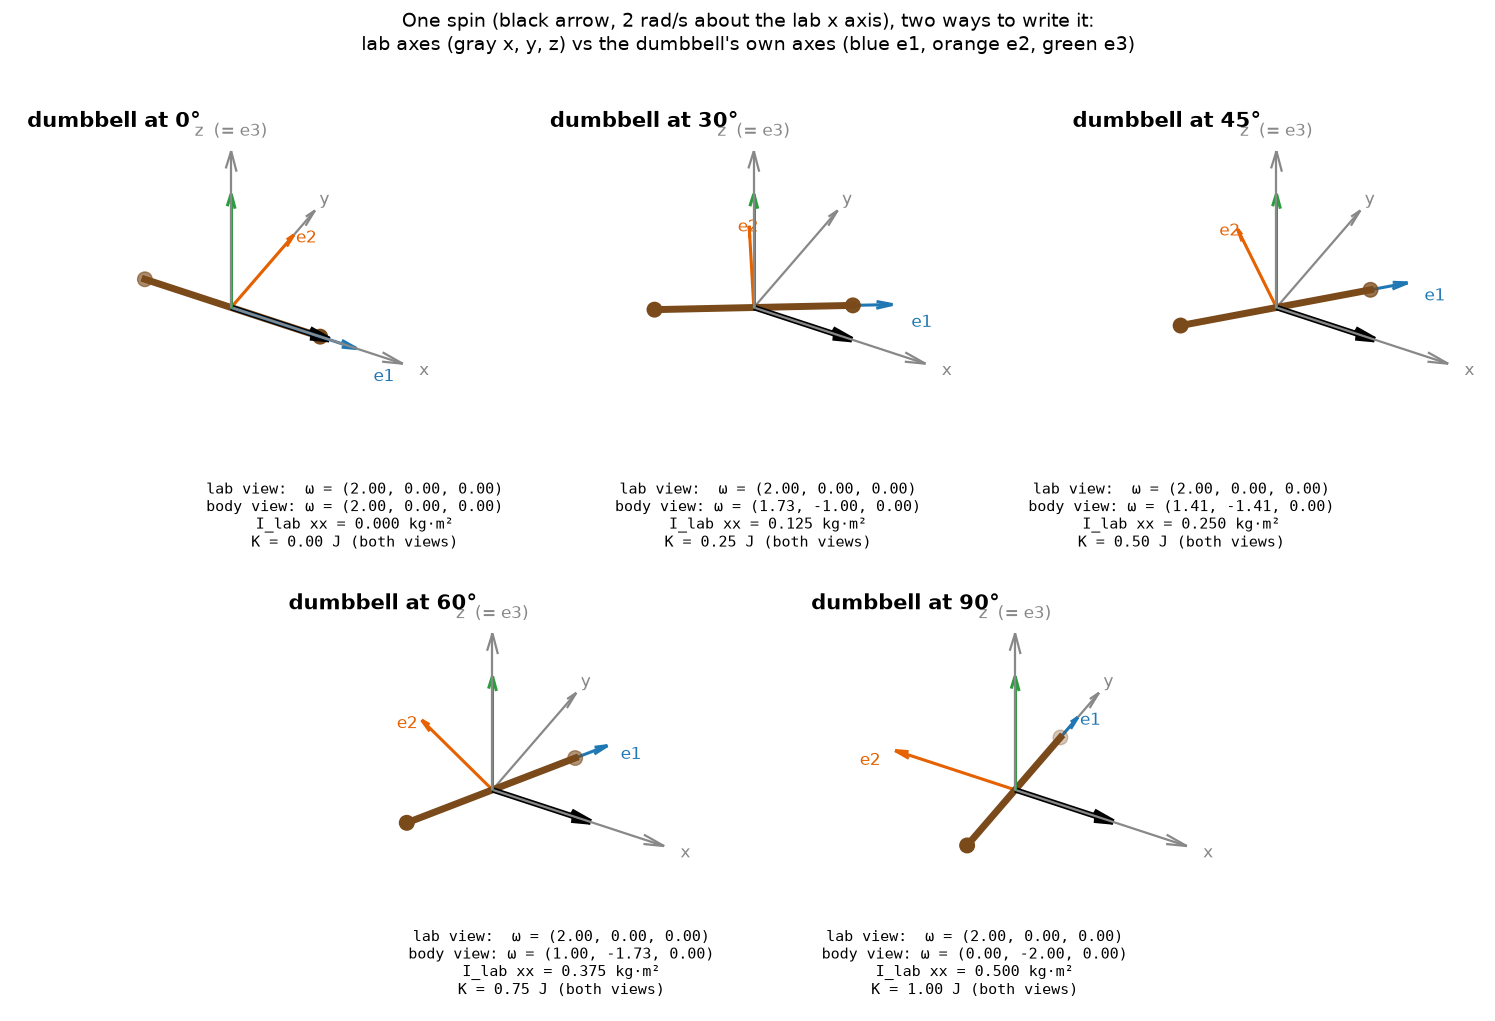

In [3]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: one physical spin, five dumbbell orientations
#   What we have: spin omega = 2 rad/s about the lab x axis, dumbbell (two 1 kg masses at +-0.5 m)
#                 at angle alpha from the lab x axis in the xy plane
#   What we want: the spin written in lab axes and in the dumbbell's own (body) axes
#   Why: to see that the SAME spin has DIFFERENT numbers in the two views
#   R = [e1 e2 e3] (columns = body axes in lab coordinates)
#   omega_body = R^T omega_lab,   I_lab = R I_body R^T
# ---------------------------------------------------------------
OMEGA_LAB = np.array([2.0, 0.0, 0.0])
I_BODY = np.diag([0.0, 0.5, 0.5])
ANGLES = [0, 30, 45, 60, 90]

# ---------------------------------------------------------------
# STEP 2: draw 5 panels in 2 rows (3 on top, 2 below), each in 3D with x, y, z axes
#   What we have: the formulas above
#   What we want: lab axes (gray x, y, z), body axes (blue e1, orange e2, green e3) and the spin arrow (black)
#   Why: the black arrow never changes, only the axes you read it against
#   K = 1/2 omega_lab^T I_lab omega_lab = 1/2 omega_body^T I_body omega_body
# ---------------------------------------------------------------
GRAY, BLUE, ORANGE, GREEN, BROWN = "#888888", "#1f77b4", "#e66100", "#2a9d3f", "#7a4a1a"
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(2, 6, hspace=0.12, wspace=0.0)
slots = [gs[0, 0:2], gs[0, 2:4], gs[0, 4:6], gs[1, 1:3], gs[1, 3:5]]


def arrow(ax, v, color, lw, label=None, scale=1.0, lab_off=1.12):
    ax.quiver(0, 0, 0, *(scale * v), color=color, linewidth=lw, arrow_length_ratio=0.12)
    if label:
        ax.text(*(lab_off * scale * v), label, color=color, fontsize=12, ha="center", va="center")


for slot, deg in zip(slots, ANGLES):
    ax = fig.add_subplot(slot, projection="3d")
    a = np.deg2rad(deg)
    R = np.array([[np.cos(a), -np.sin(a), 0.0], [np.sin(a), np.cos(a), 0.0], [0.0, 0.0, 1.0]])
    e1, e2, e3 = R[:, 0], R[:, 1], R[:, 2]
    w_body = R.T @ OMEGA_LAB
    I_lab = R @ I_BODY @ R.T
    K_lab = 0.5 * OMEGA_LAB @ I_lab @ OMEGA_LAB
    K_body = 0.5 * w_body @ I_BODY @ w_body
    assert abs(K_lab - K_body) < 1e-12
    for v, lab in ((np.array([1.0, 0, 0]), "x"), (np.array([0, 1.0, 0]), "y"), (np.array([0, 0, 1.0]), "z")):
        arrow(ax, v, GRAY, 1.6, "z  (= e3)" if lab == "z" else lab, scale=0.95, lab_off=1.12)
    arrow(ax, e1, BLUE, 2.2, None, scale=0.7)
    ax.text(*(0.7 * 1.22 * e1 + np.array([0, 0, -0.12])), "e1", color=BLUE, fontsize=12, ha="center", va="center")
    arrow(ax, e2, ORANGE, 2.2, None, scale=0.7)
    ax.text(*(0.7 * 1.22 * e2 + np.array([0, 0, -0.12])), "e2", color=ORANGE, fontsize=12, ha="center", va="center")
    arrow(ax, e3, GREEN, 2.2, None, scale=0.7)
    p = 0.5 * e1
    ax.plot([-p[0], p[0]], [-p[1], p[1]], [-p[2], p[2]], color=BROWN, lw=5, zorder=5)
    ax.scatter([-p[0], p[0]], [-p[1], p[1]], [-p[2], p[2]], s=110, color=BROWN, zorder=6)
    ax.quiver(0, 0, 0, 0.55, 0, 0, color="black", linewidth=4, arrow_length_ratio=0.2)
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.set_zlim(-1, 1)
    ax.set_box_aspect((1, 1, 1), zoom=1.55)
    ax.view_init(elev=38, azim=-62)
    ax.set_axis_off()
    txt = (f"lab view:  ω = (2.00, 0.00, 0.00)\n"
           f"body view: ω = ({w_body[0]:.2f}, {w_body[1]:.2f}, {w_body[2]:.2f})\n"
           f"I_lab xx = {I_lab[0, 0]:.3f} kg·m²\n"
           f"K = {K_lab:.2f} J (both views)")
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y0 + 0.035, txt, ha="center", va="top", fontsize=10.5, family="monospace")
    ax.text2D(0.04, 0.97, f"dumbbell at {deg}°", transform=ax.transAxes, ha="left", va="top", fontsize=15, fontweight="bold")

fig.suptitle("One spin (black arrow, 2 rad/s about the lab x axis), two ways to write it:\n"
             "lab axes (gray x, y, z) vs the dumbbell's own axes (blue e1, orange e2, green e3)", fontsize=14)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.07)
out_path = os.path.join(RESULT_DIR, f"lab_vs_body_transition_{TIMESTAMP}.png")
plt.savefig(out_path, dpi=150)
print("saved the figure")
plt.show()

saved the figure


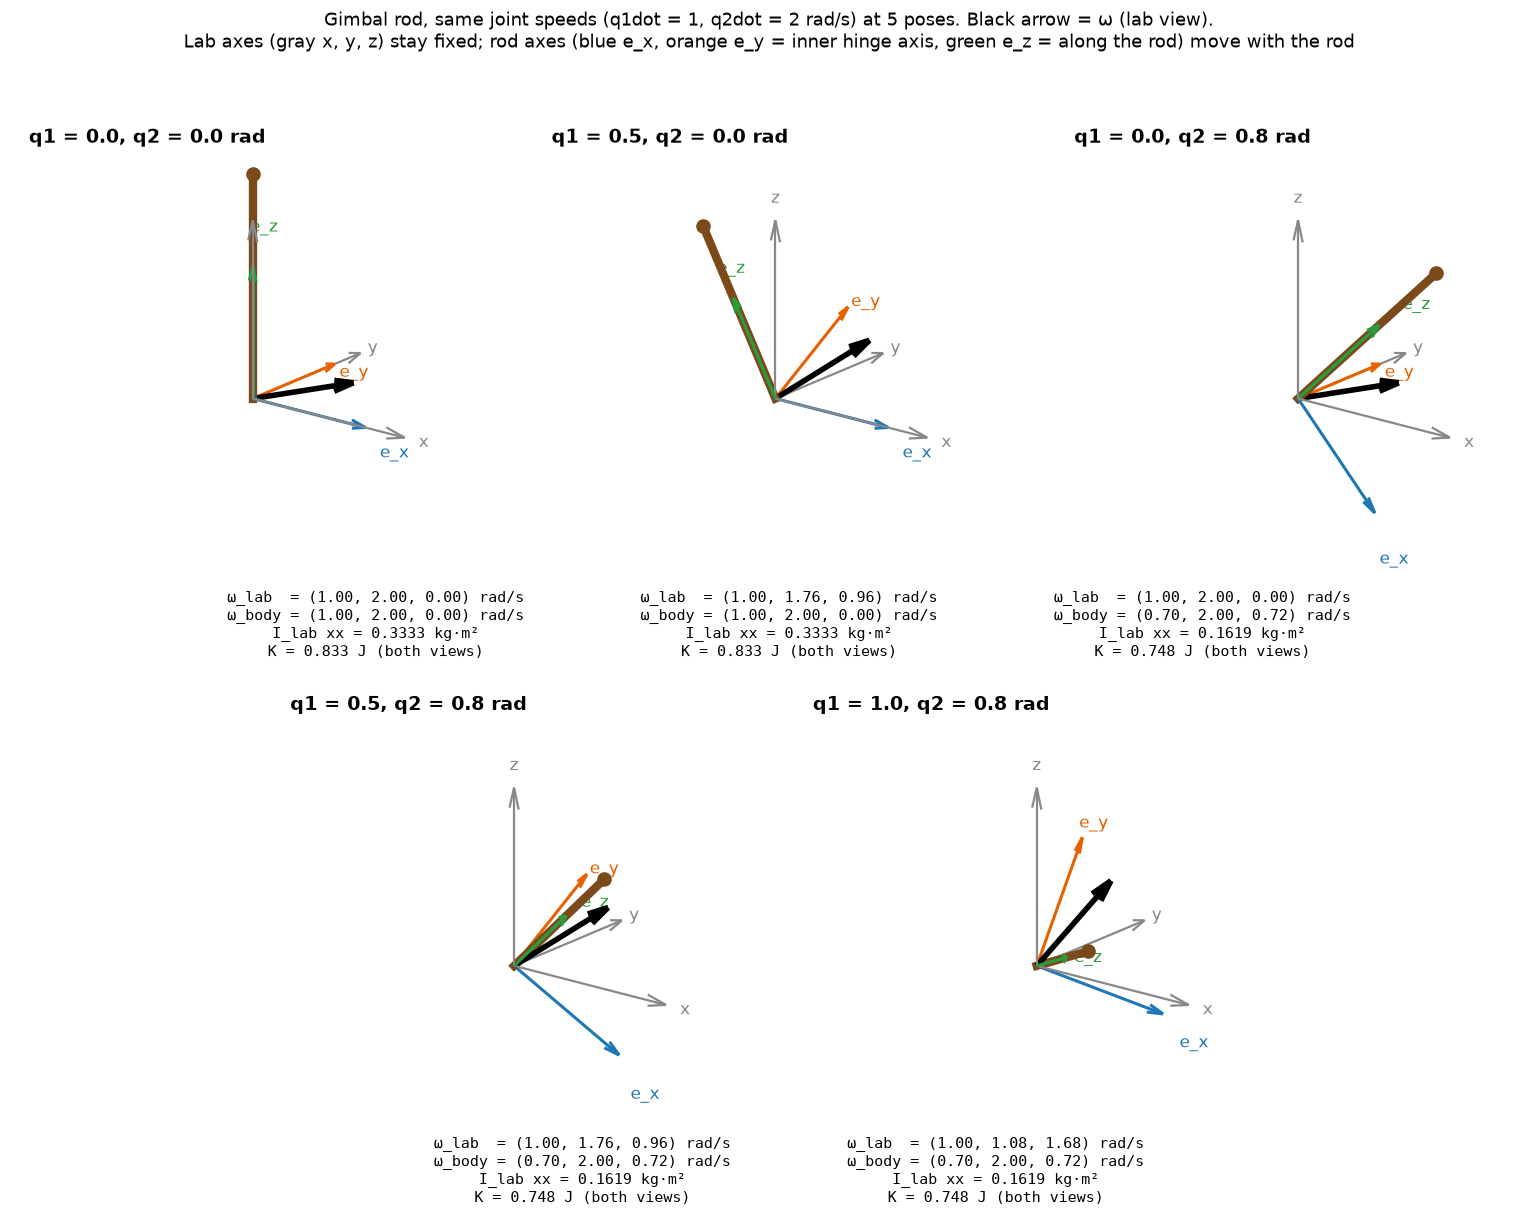

In [4]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the gimbal rod and its inertia
#   What we have: rod m = 1 kg, L = 1 m, r = 0.02 m, hinges at the pivot:
#                 outer hinge about lab x_hat (angle q1), inner hinge about a2 = Rx(q1) y_hat (angle q2)
#   What we want: inertia matrix about the pivot in the rod's own (body) axes
#   Why: in body axes it is diagonal and constant
#   I_pivot = m L^2/12 + m (L/2)^2 = 1/3 kg m^2 (across the rod),  I_zz = m r^2/2 (along the rod)
# ---------------------------------------------------------------
M_ROD, L_ROD, R_ROD = 1.0, 1.0, 0.02
I_PIV = M_ROD * L_ROD**2 / 12 + M_ROD * (L_ROD / 2) ** 2
I_ZZ = M_ROD * R_ROD**2 / 2
I_BODY = np.diag([I_PIV, I_PIV, I_ZZ])
QDOT = np.array([1.0, 2.0])  # (q1dot, q2dot) rad/s
POSES = [(0.0, 0.0), (0.5, 0.0), (0.0, 0.8), (0.5, 0.8), (1.0, 0.8)]


def Rx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def Ry(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


# ---------------------------------------------------------------
# STEP 2: lab view and body view of the same motion
#   What we have: q1, q2, q1dot, q2dot
#   What we want: omega and K in both views
#   Why: to see that the two views agree on K but not on the numbers
#   R = Rx(q1) Ry(q2) = [e_x e_y e_z] (columns = rod axes in lab coordinates)
#   omega_lab = q1dot x_hat + q2dot a2,   omega_body = R^T omega_lab
#   I_lab = R I_body R^T,   K = 1/2 omega_lab^T I_lab omega_lab = 1/2 omega_body^T I_body omega_body
# ---------------------------------------------------------------
GRAY, BLUE, ORANGE, GREEN, BROWN = "#888888", "#1f77b4", "#e66100", "#2a9d3f", "#7a4a1a"
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(2, 6, hspace=0.2, wspace=0.0)
slots = [gs[0, 0:2], gs[0, 2:4], gs[0, 4:6], gs[1, 1:3], gs[1, 3:5]]


def arrow(ax, v, color, lw, label=None, scale=1.0, lab_off=1.12, shift=(0, 0, 0)):
    ax.quiver(0, 0, 0, *(scale * np.asarray(v)), color=color, linewidth=lw, arrow_length_ratio=0.12)
    if label:
        ax.text(*(lab_off * scale * np.asarray(v) + np.asarray(shift)), label, color=color,
                fontsize=12, ha="center", va="center")


for slot, (q1, q2) in zip(slots, POSES):
    ax = fig.add_subplot(slot, projection="3d")
    R = Rx(q1) @ Ry(q2)
    a2 = Rx(q1) @ np.array([0.0, 1.0, 0.0])
    w_lab = QDOT[0] * np.array([1.0, 0.0, 0.0]) + QDOT[1] * a2
    w_body = R.T @ w_lab
    I_lab = R @ I_BODY @ R.T
    K_lab = 0.5 * w_lab @ I_lab @ w_lab
    K_body = 0.5 * w_body @ I_BODY @ w_body
    assert abs(K_lab - K_body) < 1e-12
    for v, lab in ((np.array([1.0, 0, 0]), "x"), (np.array([0, 1.0, 0]), "y"), (np.array([0, 0, 1.0]), "z")):
        arrow(ax, v, GRAY, 1.6, lab, scale=0.8, lab_off=1.12)
    arrow(ax, R[:, 0], BLUE, 2.2, "e_x", scale=0.6, lab_off=1.25, shift=(0, 0, -0.08))
    arrow(ax, R[:, 1], ORANGE, 2.2, "e_y", scale=0.6, lab_off=1.25, shift=(0, 0, -0.08))
    arrow(ax, R[:, 2], GREEN, 2.2, "e_z", scale=0.6, lab_off=1.3, shift=(0.06, 0, 0))
    tip = L_ROD * R[:, 2]
    ax.plot([0, tip[0]], [0, tip[1]], [0, tip[2]], color=BROWN, lw=6, zorder=5)
    ax.scatter(*tip, s=90, color=BROWN, zorder=6)
    ax.quiver(0, 0, 0, *(0.22 * w_lab), color="black", linewidth=4, arrow_length_ratio=0.2)
    ax.set_xlim(-0.8, 0.8)
    ax.set_ylim(-0.8, 0.8)
    ax.set_zlim(-0.6, 1.1)
    ax.set_box_aspect((1.6, 1.6, 1.7), zoom=1.35)
    ax.view_init(elev=18, azim=-52)
    ax.set_axis_off()
    txt = (f"ω_lab  = ({w_lab[0]:.2f}, {w_lab[1]:.2f}, {w_lab[2]:.2f}) rad/s\n"
           f"ω_body = ({w_body[0]:.2f}, {w_body[1]:.2f}, {w_body[2]:.2f}) rad/s\n"
           f"I_lab xx = {I_lab[0, 0]:.4f} kg·m²\n"
           f"K = {K_lab:.3f} J (both views)")
    pos = ax.get_position()
    fig.text((pos.x0 + pos.x1) / 2, pos.y0 - 0.012, txt, ha="center", va="top", fontsize=10.5, family="monospace")
    ax.text2D(0.04, 0.97, f"q1 = {q1}, q2 = {q2} rad", transform=ax.transAxes, ha="left", va="top",
              fontsize=14, fontweight="bold")

fig.suptitle("Gimbal rod, same joint speeds (q1dot = 1, q2dot = 2 rad/s) at 5 poses. Black arrow = ω (lab view).\n"
             "Lab axes (gray x, y, z) stay fixed; rod axes (blue e_x, orange e_y = inner hinge axis, green e_z = along the rod) move with the rod",
             fontsize=13)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.1)
out_path = os.path.join(RESULT_DIR, f"gimbal_lab_vs_body_{TIMESTAMP}.png")
plt.savefig(out_path, dpi=150)
print("saved the figure")
plt.show()